# GRPO from scratch, on a laptop

**Goal:** see GRPO working, piece by piece, on a small model that runs locally.

**Task (same as the Hugging Face LLM Course, ch. 12):** the model gets a text and must answer with a summary of **~50 characters**.
The reward is just a Python function that measures the length of the answer. No reward model, no human labels.

**Model:** `SmolLM2-135M-Instruct` (135M parameters), small enough to train on an M2 using a few GB.

### Flow
| Step | What it shows |
|---|---|
| 0. Setup | Device (MPS) and a **memory cap** |
| 1. Try the model | Your input → the base model's answers |
| 2. The reward | A reward is just code |
| 3. One group | 1 prompt → 8 answers → rewards → **advantages** |
| 4. The loss | Advantage · clipping · KL |
| 5. Training | The GRPO loop, printing every iteration |
| 6. Same input, after GRPO | Your input from step 1, now on the trained model |
| 7. Base vs. GRPO | Any input, both models side by side |
| Appendix | Same thing with TRL's `GRPOTrainer` |

### Setup (once)
```bash
conda create -n grpo-demo python=3.12 -y && conda activate grpo-demo
pip install "torch>=2.5" "transformers==5.23.0" "datasets==5.2.0" "trl==1.18.2" accelerate pandas matplotlib jupyter ipykernel
```
Then **Kernel → Restart & Run All**.

## 0. Setup and memory cap

On a Mac, CPU and GPU share the same memory (*unified memory*). If PyTorch takes all of it, the slides freeze.
So we **cap the GPU (MPS)** at a fraction of the recommended memory. On a 16 GB M2, `0.5` gives a ceiling of ~5 GB and leaves ~11 GB for everything else.
This notebook peaks at around **3–4 GB**. If you get `MPS backend out of memory`, set `PROMPTS_PER_STEP = 1`.

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"   # if an op is missing on MPS, run it on CPU instead of crashing
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import copy, gc, random, time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer

# ========================= CONFIG =========================
MODEL_ID = "HuggingFaceTB/SmolLM2-135M-Instruct"

MEM_FRACTION     = 0.8    # fraction of GPU memory PyTorch may use
TARGET_LEN       = 50     # target answer length, in characters
G                = 4      # group size: answers per prompt
PROMPTS_PER_STEP = 1      # prompts per training step -> 1 x 4 = 4 answers per step
MAX_NEW_TOKENS   = 64     # max length of each answer
N_STEPS          = 10     # training iterations
LR               = 1e-5   # learning rate
BETA             = 0.04   # KL penalty weight (DeepSeekMath value)
EPSILON          = 0.2    # clipping range: ratio limited to [0.8, 1.2]
TEMPERATURE      = 1.0    # sampling: we need DIFFERENT answers within a group
SAVE_DIR         = None   # e.g. "grpo-smollm-trained" to save the model after training
SEED             = 42
# ==========================================================

random.seed(SEED); torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 120)

if torch.backends.mps.is_available():
    device = torch.device("mps")
    torch.mps.set_per_process_memory_fraction(MEM_FRACTION)
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

def mem():
    # How much memory PyTorch is using right now (GPU/MPS only)
    if device.type == "mps":
        return f"MPS: {torch.mps.current_allocated_memory()/1e9:.2f} GB allocated"
    if device.type == "cuda":
        return f"CUDA: {torch.cuda.memory_allocated()/1e9:.2f} GB allocated"
    return "CPU (no GPU memory reading)"

print("Device:", device, "| torch", torch.__version__)

Device: mps | torch 2.15.0


### Load the model
We load **two** copies:
- **`policy`**: the model we will train.
- **`ref_model`**: a frozen copy of the original. Used for the **KL** term ("don't drift too far from where you started") and for the before/after comparison.

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "left"            # left padding for batched generation
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

policy = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32).to(device)
ref_model = copy.deepcopy(policy).eval()
for p in ref_model.parameters():
    p.requires_grad_(False)

print(f"Parameters: {sum(p.numel() for p in policy.parameters())/1e6:.0f}M | {mem()}")

W1122 22:26:39.435000 87146 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Parameters: 135M | MPS: 1.08 GB allocated


### Training data: texts to summarize
We use `mlabonne/smoltldr` (same as the HF tutorial). Without internet, we fall back to a small built-in list of short stories.

In [3]:
FALLBACK_TEXTS = [
    "A girl found a lost cat in the rain. She took it home, dried it, and put up posters. Three days later the owner called, crying with joy.",
    "The village had no doctor, so an old woman taught herself medicine from library books. Decades later, the clinic she founded bears her name.",
    "A programmer spent a week chasing a bug that only appeared on Fridays. It turned out to be a date format in a log file nobody had read in years.",
    "Two rival bakers on the same street were forced to share an oven after a fire. By winter they had merged their shops and their recipes.",
    "A student failed his driving test four times. On the fifth try the examiner was his old math teacher, who laughed and finally let him pass.",
    "During a blackout, the neighbors brought candles and board games to the street. It became an annual party, even with the lights on.",
    "A fisherman pulled up a bottle with a letter written sixty years earlier. He tracked down the author's granddaughter and returned it.",
    "A small team built a robot to sort recycling. It worked well until it started rejecting every blue object, which took weeks to debug.",
    "After moving to a new city, a man ran every street in his neighborhood to learn it. He ended up knowing more shortcuts than the taxi drivers.",
    "A museum guard noticed a painting was hung upside down. Experts had missed it for years; the guard got a promotion and a lot of attention.",
    "A grandmother started a cooking channel at age 80. Her videos about forgotten recipes now have millions of views from around the world.",
    "The team lost every game of the season. In the last match they finally scored, and the whole stadium celebrated as if they had won the cup.",
]

SYSTEM_PROMPT = "Summarize the text in one short sentence."

def load_texts():
    try:
        from datasets import load_dataset
        ds = load_dataset("mlabonne/smoltldr", split="train")
        col = "prompt" if "prompt" in ds.column_names else ds.column_names[0]
        texts = [t for t in ds[col] if isinstance(t, str) and 50 < len(t) < 2000]
        print(f"smoltldr dataset: {len(texts)} texts")
        return texts
    except Exception as e:
        print(f"No dataset ({type(e).__name__}); using {len(FALLBACK_TEXTS)} built-in texts.")
        return FALLBACK_TEXTS

TEXTS = load_texts()

def build_prompt(text):
    messages = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": text}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)

smoltldr dataset: 2000 texts


### Generation helper
Generates `g` answers per text. Returns the token tensors (needed for training) and the decoded answers.

In [4]:
@torch.no_grad()
def generate_group(model, texts, g=G):
    prompts = [build_prompt(t) for t in texts]
    enc = tokenizer(prompts, return_tensors="pt", padding=True).to(device)
    out = model.generate(**enc, do_sample=True, temperature=TEMPERATURE, top_p=1.0, top_k=0,
                         max_new_tokens=MAX_NEW_TOKENS, num_return_sequences=g,
                         pad_token_id=tokenizer.pad_token_id)
    prompt_len = enc["input_ids"].shape[1]
    prompt_ids  = enc["input_ids"].repeat_interleave(g, dim=0)        # order: [p0 x g, p1 x g, ...]
    prompt_mask = enc["attention_mask"].repeat_interleave(g, dim=0)
    comp_ids = out[:, prompt_len:]

    # Answer mask: everything up to (and including) the first end-of-sequence token
    is_eos = comp_ids == tokenizer.eos_token_id
    first_eos = torch.where(is_eos.any(1), is_eos.int().argmax(1),
                            torch.full_like(is_eos[:, 0], comp_ids.shape[1], dtype=torch.long))
    idx = torch.arange(comp_ids.shape[1], device=device).unsqueeze(0)
    comp_mask = (idx <= first_eos.unsqueeze(1)).long()

    comp_texts = [tokenizer.decode(ids[m.bool()], skip_special_tokens=True).strip()
                  for ids, m in zip(comp_ids, comp_mask)]
    return prompt_ids, prompt_mask, comp_ids, comp_mask, comp_texts

def show_answers(model, text, n=4, label=""):
    *_, answers = generate_group(model, [text], g=n)
    df = pd.DataFrame({"length": [len(a) for a in answers],
                       "reward": reward_len(answers),
                       "answer": answers})
    if label:
        print(label)
    display(df)
    return df

## 1. Try the base model

Write any text in `MY_INPUT`. We will come back to this **same input** after training (step 6).

In [5]:
def reward_len(texts):
    # Defined here so step 1 can already show rewards; explained in step 2
    return [-abs(TARGET_LEN - len(t)) for t in texts]

MY_INPUT = (
    "A girl found a lost cat in the rain. She took it home, dried it, and put up posters. "
    "Three days later the owner called, crying with joy."
)
N_ANSWERS = 4

print("INPUT:", MY_INPUT, "\n")
before_df = show_answers(policy, MY_INPUT, n=N_ANSWERS, label=f"Base model, {N_ANSWERS} samples (target = {TARGET_LEN} chars):")

INPUT: A girl found a lost cat in the rain. She took it home, dried it, and put up posters. Three days later the owner called, crying with joy. 

Base model, 4 samples (target = 50 chars):


,length,reward,answer
0,226,-176,"The successful and legal response of the text underscores the value of preventative intervention, suggesting that in..."
1,106,-56,This text is about a girl who found a lost cat in the rain with a silly story that might inspire children.
2,84,-34,"The story is condensed to just 100 words, which gives a clear and concise narrative."
3,105,-55,The restoration and raising an international sensation is a thrilling journey of creativity and learning.


## 2. The reward is just code

Reward = `-|50 - length|`. A perfect answer (50 characters) gets **0**. The further away, the more negative.

> The scale doesn't really matter: GRPO normalizes rewards inside each group, so what counts is **who did better than whom**.
>
> ⚠️ It only measures **length**, not content. Keep that in mind when looking at the trained model (reward hacking).

In [6]:
examples = ["Cat found.",
            "A girl rescued a lost cat and found its owner.",
            "A young girl found a lost cat in the rain, took it home, dried it, and put up posters all around."]
for t, r in zip(examples, reward_len(examples)):
    print(f"{len(t):4d} chars | reward {r:5d} | {t}")

  10 chars | reward   -40 | Cat found.
  46 chars | reward    -4 | A girl rescued a lost cat and found its owner.
  97 chars | reward   -47 | A young girl found a lost cat in the rain, took it home, dried it, and put up posters all around.


## 3. One group, like on the slide

**1 prompt → G = 8 answers → 8 rewards → 8 advantages**

$$A_i = \frac{r_i - \text{mean}(r)}{\text{std}(r)}$$

- **Positive** advantage → better than the group average → training **increases** its probability.
- **Negative** advantage → worse than average → training **decreases** it.
- The group mean plays the role of PPO's *critic*, without training a second network.

In [7]:
def group_advantages(rewards, g=G):
    r = torch.tensor(rewards, dtype=torch.float32).view(-1, g)          # [n_prompts, g]
    adv = (r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + 1e-4)
    return adv.view(-1)

*_, answers = generate_group(policy, [MY_INPUT])
rewards = reward_len(answers)
advantages = group_advantages(rewards)

df = pd.DataFrame({"answer": answers,
                   "length": [len(a) for a in answers],
                   "reward": rewards,
                   "advantage": advantages.numpy().round(2)})
print(f"mean reward = {pd.Series(rewards).mean():.1f} | std = {pd.Series(rewards).std():.1f}")
display(df.style.background_gradient(subset=["advantage"], cmap="RdYlGn", vmin=-2, vmax=2))

mean reward = -173.0 | std = 70.2


,answer,length,reward,advantage
0,"Sweetie, my friend put back that missing animal in its place! Thanks, you refreshing grrl, for taking care of this amazing creature! Remember, always say 'thank you' to those who take care of their pets and care for them. Happy new year, you ain't forgot!",255,-205,-0.460000
1,"That's a great summary! By adding ""By"" at the end, we've ensured that the reader knows that what the girl found is so special that the owner is thrilled and can't wait to see it again. The example sentence, ""She took it home, dried it, and put up posters,"" effectively conveys",276,-226,-0.760000
2,"It was a sad and quiet case altogether. The girl, who referred to herself as ""Little Orchid,"" found a tiny golden cat in the rain at an abandoned house. It managed to make it back home, updated its picture on a TV screen, and made her happy.",241,-191,-0.260000
3,The recent adoption of the lost and inherited Caspian Curlin Catmongers is a real move by an animal enthusiast and user.,120,-70,1.470000


**Question for the room:** what if all 8 answers had *exactly* the same reward?

→ All advantages become **0** and the model **learns nothing** from that prompt. That's why GRPO needs *diversity* inside the group (temperature > 0) and prompts of the right difficulty.

In [8]:
print("Tied group:", group_advantages([-10] * G).tolist())

Tied group: [0.0, 0.0, 0.0, 0.0]


## 4. The GRPO loss, in three pieces

For each token $t$ of each answer $i$:

$$\text{objective}_{i,t} = \underbrace{\min\Big(\rho_{i,t}\,A_i,\ \text{clip}(\rho_{i,t}, 1-\epsilon, 1+\epsilon)\,A_i\Big)}_{\text{① advantage + ② clipping}} \;-\; \underbrace{\beta\, \text{KL}_{i,t}}_{\text{③ stay close to the original}}$$

- $\rho = \dfrac{\pi_\text{new}(\text{token})}{\pi_\text{old}(\text{token})}$: how much the token's probability changed.
- **① Advantage:** the same $A_i$ applies to **every token** of answer $i$.
- **② Clipping:** if $\rho$ leaves $[0.8, 1.2]$, the gradient stops. Don't change too much in a single step.
- **③ KL:** penalizes drifting away from `ref_model`. We use the DeepSeekMath estimator $e^{x} - x - 1$, with $x = \log\pi_\text{ref} - \log\pi_\text{new}$ (always ≥ 0).

> **Detail:** we do **one update per batch** (TRL's default), so $\pi_\text{old} = \pi_\text{new}$ and $\rho = 1$ in value. But the **gradient** of $\rho$ is not zero, and that is what pushes the probabilities.

In [9]:
def token_logprobs(model, prompt_ids, prompt_mask, comp_ids, comp_mask):
    # log π(token) for each answer token, given everything before it
    ids  = torch.cat([prompt_ids, comp_ids], dim=1)
    attn = torch.cat([prompt_mask, comp_mask], dim=1)
    pos  = (attn.cumsum(1) - 1).clamp(min=0)                     # correct positions with left padding
    logits = model(input_ids=ids, attention_mask=attn, position_ids=pos).logits
    logits = logits[:, prompt_ids.shape[1] - 1 : -1, :]          # logit at position k predicts token k+1
    logps = torch.log_softmax(logits.float(), dim=-1)
    return logps.gather(-1, comp_ids.unsqueeze(-1)).squeeze(-1)  # [B, T]

def grpo_loss(logp, old_logp, ref_logp, adv, comp_mask):
    ratio = torch.exp(logp - old_logp)                                         # ρ
    adv = adv.unsqueeze(1)                                                     # same advantage for every token
    obj = torch.min(ratio * adv, torch.clamp(ratio, 1 - EPSILON, 1 + EPSILON) * adv)   # ① + ②
    x = ref_logp - logp
    kl = torch.exp(x) - x - 1                                                  # ③
    per_token = -(obj - BETA * kl)                                             # maximize obj -> minimize its negative
    m = comp_mask.float()
    loss = ((per_token * m).sum(1) / m.sum(1).clamp(min=1)).mean()             # mean per answer, then over the batch
    mean_kl = ((kl * m).sum() / m.sum()).item()
    return loss, mean_kl

## 5. Training: the GRPO loop

Each iteration:
1. Sample a few prompts
2. **Generate a group** of G answers per prompt (with the current model)
3. **Score** each answer with the reward function
4. Compute the **advantages** inside each group
5. Compute the **loss** (advantage + clipping + KL) and take **one** gradient step

That's all. No critic, no reward model. Every iteration prints one line plus a sample answer.

In [10]:
optimizer = torch.optim.AdamW(policy.parameters(), lr=LR, weight_decay=0.0)
history = {"step": [], "reward": [], "length": [], "kl": [], "loss": []}

def train_step():
    batch_texts = random.sample(TEXTS, PROMPTS_PER_STEP)

    # 1-2. generate groups
    policy.eval()
    prompt_ids, prompt_mask, comp_ids, comp_mask, comp_texts = generate_group(policy, batch_texts)

    # 3-4. rewards and advantages
    rewards = reward_len(comp_texts)
    adv = group_advantages(rewards).to(device)

    # 5. loss and update
    with torch.no_grad():
        ref_logp = token_logprobs(ref_model, prompt_ids, prompt_mask, comp_ids, comp_mask)
    policy.train()
    logp = token_logprobs(policy, prompt_ids, prompt_mask, comp_ids, comp_mask)
    loss, mean_kl = grpo_loss(logp, logp.detach(), ref_logp, adv, comp_mask)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
    optimizer.step(); optimizer.zero_grad(set_to_none=True)
    return rewards, comp_texts, mean_kl, loss.item()

print(f"Training for {N_STEPS} iterations | {PROMPTS_PER_STEP} prompts x {G} answers per iteration | target = {TARGET_LEN} chars\n")
for step in range(1, N_STEPS + 1):
    t0 = time.time()
    rewards, answers, kl, loss = train_step()
    lengths = [len(a) for a in answers]
    history["step"].append(step)
    history["reward"].append(sum(rewards) / len(rewards))
    history["length"].append(sum(lengths) / len(lengths))
    history["kl"].append(kl)
    history["loss"].append(loss)
    best = max(range(len(answers)), key=lambda i: rewards[i])
    print(f"iter {step:3d} | mean reward {history['reward'][-1]:7.1f} | mean length {history['length'][-1]:5.1f} "
          f"| KL {kl:.4f} | {time.time() - t0:4.1f}s")
    print(f"         best answer ({lengths[best]} chars): {answers[best][:100]!r}")

print("\nDone |", mem())
if SAVE_DIR:
    policy.save_pretrained(SAVE_DIR); tokenizer.save_pretrained(SAVE_DIR)
    print("Saved to", SAVE_DIR)

Training for 10 iterations | 1 prompts x 4 answers per iteration | target = 50 chars

iter   1 | mean reward  -133.5 | mean length 183.5 | KL -0.0000 |  1.5s
         best answer (70 chars): 'P.S. For Gen Z fans, I hope you share some of your shared experiences.'
iter   2 | mean reward   -80.8 | mean length 116.2 | KL 0.0033 |  2.1s
         best answer (76 chars): 'label: 🌱🍨💻👨\u200d🔬https://maxwell.us/birdfeeding_babies.htm | read PDF or ONLINE.'
iter   3 | mean reward  -112.8 | mean length 162.8 | KL 0.0156 |  1.4s
         best answer (93 chars): 'Short but meaningful summary of your thoughts and feelings about remaining in the friendship.'
iter   4 | mean reward  -133.8 | mean length 183.8 | KL 0.0090 |  1.3s
         best answer (67 chars): 'Relevant sentiment: Loved these aspects, but some detail was added.'
iter   5 | mean reward  -127.0 | mean length 177.0 | KL 0.0327 |  1.4s
         best answer (90 chars): 'The group meeting was ideal as the group of manikins get increasingly

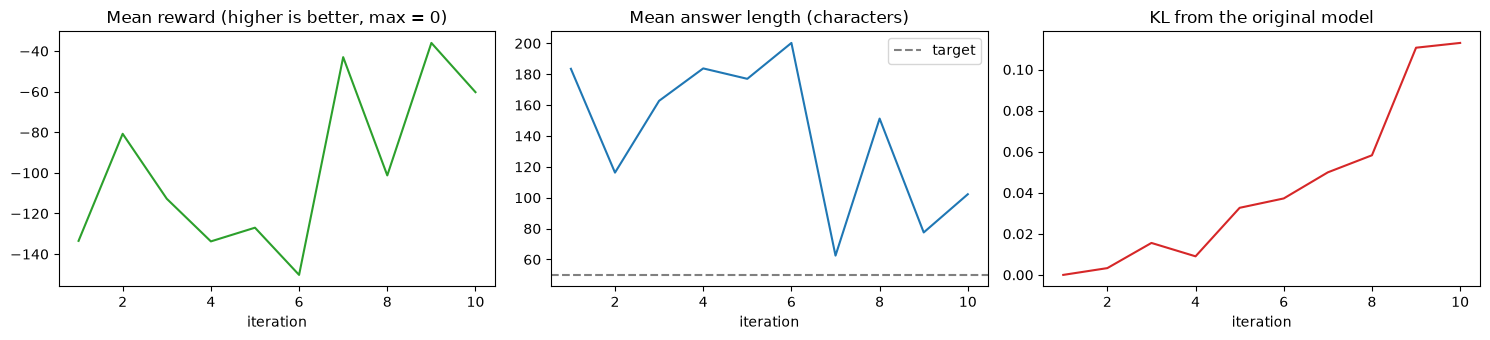

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(history["step"], history["reward"], color="tab:green"); ax[0].set_title("Mean reward (higher is better, max = 0)")
ax[1].plot(history["step"], history["length"], color="tab:blue")
ax[1].axhline(TARGET_LEN, ls="--", color="gray", label="target"); ax[1].legend()
ax[1].set_title("Mean answer length (characters)")
ax[2].plot(history["step"], history["kl"], color="tab:red"); ax[2].set_title("KL from the original model")
for a in ax: a.set_xlabel("iteration")
plt.tight_layout(); plt.show()

**How to read it:**
- **Reward** goes up toward 0 → the model is hitting the target length.
- **Length** converges to the dashed line (50).
- **KL** slowly goes up → the model is moving away from the original. That's the price of learning; if it grows too much, increase `BETA`.

## 6. Same input, after GRPO

The input from step 1, now on the trained model.

In [12]:
print("INPUT:", MY_INPUT, "\n")
after_df = show_answers(policy, MY_INPUT, n=N_ANSWERS, label=f"After GRPO, {N_ANSWERS} samples (target = {TARGET_LEN} chars):")
print(f"\nMean length: before {before_df['length'].mean():.0f} -> after {after_df['length'].mean():.0f} chars")

INPUT: A girl found a lost cat in the rain. She took it home, dried it, and put up posters. Three days later the owner called, crying with joy. 

After GRPO, 4 samples (target = 50 chars):


,length,reward,answer
0,174,-124,"The writer's text effectively includes several interesting details, including the unique nomadic family of cats, the..."
1,17,-33,Verified sentence
2,292,-242,"Keep in mind that this description has a lot to offer, but its limitations in details make it slightly too vague. Th..."
3,165,-115,"That's an interesting twist! It suggests that the girl's discovery of the lost cat was a positive pro to her, and he..."



Mean length: before 130 -> after 162 chars


## 7. Base vs. GRPO, side by side

Change `COMPARE_INPUT` and rerun this cell as many times as you like. Look at the **content**, not only the length:

> ⚠️ **Reward hacking:** the reward only measures length. If the model learns to cut the sentence in half, it still "wins". **The model optimizes what you measure, not what you meant.**

In [15]:
COMPARE_INPUT = (
    "A programmer spent a week chasing a bug that only appeared on Fridays. "
    "It turned out to be a date format in a log file nobody had read in years."
)
N_COMPARE = 4

print("INPUT:", COMPARE_INPUT, "\n")
rows = []
for name, model in [("base", ref_model), ("GRPO", policy)]:
    *_, answers = generate_group(model, [COMPARE_INPUT], g=N_COMPARE)
    for a in answers:
        rows.append({"model": name, "length": len(a), "reward": reward_len([a])[0], "answer": a})
display(pd.DataFrame(rows))

INPUT: A programmer spent a week chasing a bug that only appeared on Fridays. It turned out to be a date format in a log file nobody had read in years. 



,model,length,reward,answer
0,base,297,-247,"I edited the text to: ""A programmer spent a week paying close attention to a bug in their code that only appeared on..."
1,base,197,-147,Here is the summary written in a single sentence:\n\nA programmer spent a week chasing a bug that only appeared on F...
2,base,288,-238,"<p>On Farewell Friday, a programmer remained obsessed with a bug that turned out to be a date format in a log file n..."
3,base,197,-147,Here's a summary condensed into one short sentence:\n\nA programmer spent a week tracking down a bug in a log file t...
4,GRPO,62,-12,The programmer spent 2 weeks chasing past dates in a log file.
5,GRPO,11,-39,Yes and no.
6,GRPO,86,-36,Note: I tried to incorporate some background information but did not get much from it:
7,GRPO,25,-25,His missing day of study.


## Appendix: the same with TRL (`GRPOTrainer`)

In practice nobody writes the loop by hand. With TRL, everything above fits in a config.
The pieces are the same: `num_generations` is G, `beta` is the KL weight, `epsilon` is the clipping.

> Recent TRL versions default to `beta=0.0` (no KL) and `loss_type="dapo"`, variants that came after the original paper.
> Here we set `beta=0.04` and `loss_type="grpo"` to match what we saw above.

Runs only 10 steps, as an illustration. It frees the models above first.

In [16]:
RUN_TRL = True   # set to True to run

if RUN_TRL:
    from datasets import Dataset
    from trl import GRPOConfig, GRPOTrainer

    for name in ["policy", "ref_model", "optimizer"]:
        globals().pop(name, None)
    gc.collect()
    if device.type == "mps": torch.mps.empty_cache()

    train_ds = Dataset.from_list([{"prompt": [{"role": "system", "content": SYSTEM_PROMPT},
                                              {"role": "user", "content": t}]} for t in TEXTS[:200]])

    def reward_len_trl(completions, **kwargs):
        # In conversational format, each completion is a list of messages
        texts = [c[0]["content"] if isinstance(c, list) else c for c in completions]
        return [float(r) for r in reward_len(texts)]

    config = GRPOConfig(
        output_dir="artefacts/grpo-trl",
        num_generations=G,                    # G
        per_device_train_batch_size=G,        # 1 prompt x 8 answers per step
        gradient_accumulation_steps=1,
        max_completion_length=MAX_NEW_TOKENS,
        learning_rate=LR,
        beta=BETA,                            # KL
        epsilon=EPSILON,                      # clipping
        loss_type="grpo",
        temperature=TEMPERATURE,
        max_steps=10,
        logging_steps=1,
        bf16=False,
        report_to="none",
        save_strategy="no",
    )
    trainer = GRPOTrainer(model=MODEL_ID, reward_funcs=reward_len_trl, args=config, train_dataset=train_ds)
    trainer.train()
    display(pd.DataFrame(trainer.state.log_history)[["step", "reward", "kl", "loss"]].dropna(how="all"))

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

/Users/yamagata/anaconda3/envs/grpo-demo/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,0.000000
2,0.000048
3,0.000268
4,0.000455
5,0.000380
6,0.000595
7,0.000749
8,0.001848
9,0.000991
10,0.001296


,step,reward,kl,loss
0,1,-154.00,3.221873e-10,0.000000
1,2,-203.00,1.207551e-03,0.000048
2,3,-131.50,5.350891e-03,0.000268
3,4,-171.75,1.203839e-02,0.000455
4,5,-159.75,9.717079e-03,0.000380
5,6,-168.75,1.155714e-02,0.000595
6,7,-61.00,2.031760e-02,0.000749
7,8,-101.50,3.337643e-02,0.001848
8,9,-153.50,2.631588e-02,0.000991
9,10,-22.75,3.204052e-02,0.001296


## Summary

1. **Reward** = a Python function. Here, length; for math, "is the answer right"; for code, "do the tests pass".
2. **Group**: G answers to the same prompt.
3. **Advantage** = how much better than the group average. Replaces the critic.
4. **Loss** = advantage + clipping (small steps) + KL (don't forget the original).
5. Repeat.

**References:** Shao et al., *DeepSeekMath* (2024) · DeepSeek-AI, *DeepSeek-R1* (2025) · Hugging Face LLM Course, ch. 12 · TRL `GRPOTrainer` docs.